<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NBA Basketball Data](https://github.com/Query-farm/vgi-nba)

Standings, scores, schedules, box scores, play-by-play, and player and team stats.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nba/blob/main/notebooks/04_count_a_traded_season_once.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nba/blob/main/notebooks/README.md)


## Count a traded season once

**Can two row-selection policies recover the same career total without counting a traded season twice?** Resolve a fictional player through full and active indexes plus a season roster. Then compare team stints, a multi-team season total, a separate career endpoint and a selected season game log.

**Entirely synthetic local API scenario.** All people, teams, identifiers and
observations below are fictional. Three league schemas exercise the real released
worker's parsers; these are not NBA, WNBA or G League records, rankings or performance
comparisons. The first notebook separately preserves a tiny genuine recorded response.
The helper only serves declared JSON envelopes, with exact request audits; all
joins, measures and selections remain visible SQL. Identical numeric IDs deliberately
appear in different schemas, so **league plus ID** is the join key.

### Choose one local rule

`USE_SEASON_TOTAL` is a boolean. True keeps the multi-team `TOT` row when it exists and otherwise keeps team rows. False always keeps the team stints. Both are valid ways to count once; including every row is the deliberately invalid comparison.

In [1]:
USE_SEASON_TOTAL = True

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.47":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.47"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nba")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nba_examples import NBAExample

if type(USE_SEASON_TOTAL) is not bool:
    raise ValueError("USE_SEASON_TOTAL must be a boolean")
source = NBAExample("synthetic", "career")
theme()
session = connect(globals())
SOURCE = "Synthetic miniature · fictional inputs · NBA worker v0.2.0"
LEAGUE_LABELS = {"nba": "NBA", "wnba": "WNBA", "gleague": "G League"}

### Attach the released worker

The tag owns worker dependencies inside an isolated Python 3.13 environment.
Shared base tooling preserves the notebook kernel and initializes UTC plus an empty
temporary SQL-secret store with persistence disabled. First use requires Git/network
for packages and the VGI extension; these synthetic examples contact only loopback
for data. No live dataset is downloaded or substituted.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nba' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nba@v0.2.0 vgi-nba');

,Success


### Resolve identity across indexes and roster membership

Fetch `players(only_current:=false)`, `current_players` and a fixed-season
`team_roster` in each schema. The full index has three fictional people, the active
index two, and the Alpha roster two. Their keys deliberately repeat across leagues;
a name or numeric ID alone cannot safely join this combined sample. The current
index uses fixture `is_active` flags and the worker's current-season request key;
it does not claim real roster membership today. Display the join before selecting
**Ada Vale, ID 9001**, whose history is the subject of this example.

In [5]:
%%sql
CREATE TABLE all_players_nba AS SELECT * FROM nba.nba.players(only_current:=false);
CREATE TABLE all_players_wnba AS SELECT * FROM nba.wnba.players(only_current:=false);
CREATE TABLE all_players_gleague AS SELECT * FROM nba.gleague.players(only_current:=false);
CREATE TABLE all_players AS SELECT 'nba' AS league,* FROM all_players_nba UNION ALL SELECT 'wnba' AS league,* FROM all_players_wnba UNION ALL SELECT 'gleague' AS league,* FROM all_players_gleague;
CREATE TABLE active_players_nba AS SELECT * FROM nba.nba.current_players;
CREATE TABLE active_players_wnba AS SELECT * FROM nba.wnba.current_players;
CREATE TABLE active_players_gleague AS SELECT * FROM nba.gleague.current_players;
CREATE TABLE active_players AS SELECT 'nba' AS league,* FROM active_players_nba UNION ALL SELECT 'wnba' AS league,* FROM active_players_wnba UNION ALL SELECT 'gleague' AS league,* FROM active_players_gleague;
CREATE TABLE rosters_nba AS SELECT * FROM nba.nba.team_roster(7001,season:=2025);
CREATE TABLE rosters_wnba AS SELECT * FROM nba.wnba.team_roster(7001,season:=2025);
CREATE TABLE rosters_gleague AS SELECT * FROM nba.gleague.team_roster(7001,season:=2025);
CREATE TABLE rosters AS SELECT 'nba' AS league,* FROM rosters_nba UNION ALL SELECT 'wnba' AS league,* FROM rosters_wnba UNION ALL SELECT 'gleague' AS league,* FROM rosters_gleague;

,Count


In [6]:
%%sql identity <<
SELECT p.league,p.player_id,p.player_name,p.is_active,
 a.player_id IS NOT NULL AS in_current_index,r.player_id IS NOT NULL AS in_selected_roster,
 r.season AS roster_season,r.team_id AS roster_team,r.height_inches,r.experience_years,
 p.player_id=9001 AND a.player_id IS NOT NULL AND r.player_id IS NOT NULL AS chosen_history
FROM all_players p LEFT JOIN active_players a USING(league,player_id)
LEFT JOIN rosters r USING(league,player_id)
ORDER BY p.league,p.player_id;

In [7]:
display(identity)
assert int(identity.chosen_history.sum()) == 3
prose(
    f"The full indexes contain **{len(identity)}** fictional people; "
    f"**{int(identity.in_current_index.sum())}** are active and "
    f"**{int(identity.in_selected_roster.sum())}** join the selected rosters. "
    "Ada Vale resolves once per league. The historical roster is one input to identity resolution, "
    "not proof that a player stayed on that team throughout a season."
)

,league,player_id,player_name,is_active,in_current_index,in_selected_roster,roster_season,roster_team,height_inches,experience_years,chosen_history
0,gleague,9001,Ada Vale,True,True,True,2025-26,7001,72,1,True
1,gleague,9002,Bea North,True,True,True,2025-26,7001,72,1,False
2,gleague,9003,Cam Drift,False,False,False,None,<NA>,<NA>,<NA>,False
3,nba,9001,Ada Vale,True,True,True,2025-26,7001,72,1,True
4,nba,9002,Bea North,True,True,True,2025-26,7001,72,1,False
5,nba,9003,Cam Drift,False,False,False,None,<NA>,<NA>,<NA>,False
6,wnba,9001,Ada Vale,True,True,True,2025,7001,72,1,True
7,wnba,9002,Bea North,True,True,True,2025,7001,72,1,False
8,wnba,9003,Cam Drift,False,False,False,None,<NA>,<NA>,<NA>,False


The full indexes contain **9** fictional people; **6** are active and **6** join the selected rosters. Ada Vale resolves once per league. The historical roster is one input to identity resolution, not proof that a player stayed on that team throughout a season.

### Inspect the mixed grain of career rows

`player_career_stats` returns three team-season rows plus one `TOT` row that
summarizes the two stints in the later season. `player_career_totals` is a separate
career-level reference. `player_game_log` supplies five game lines for the later
season. These are independently parsed endpoint projections; we reconcile them
with visible SQL. The synthetic career has exactly two seasons and the game log is
complete for its later season, assumptions we would need to establish for real data.

In [8]:
%%sql
CREATE TABLE career_rows_nba AS SELECT * FROM nba.nba.player_career_stats(9001);
CREATE TABLE career_rows_wnba AS SELECT * FROM nba.wnba.player_career_stats(9001);
CREATE TABLE career_rows_gleague AS SELECT * FROM nba.gleague.player_career_stats(9001);
CREATE TABLE career_rows AS SELECT 'nba' AS league,* FROM career_rows_nba UNION ALL SELECT 'wnba' AS league,* FROM career_rows_wnba UNION ALL SELECT 'gleague' AS league,* FROM career_rows_gleague;
CREATE TABLE career_totals_nba AS SELECT * FROM nba.nba.player_career_totals(9001);
CREATE TABLE career_totals_wnba AS SELECT * FROM nba.wnba.player_career_totals(9001);
CREATE TABLE career_totals_gleague AS SELECT * FROM nba.gleague.player_career_totals(9001);
CREATE TABLE career_totals AS SELECT 'nba' AS league,* FROM career_totals_nba UNION ALL SELECT 'wnba' AS league,* FROM career_totals_wnba UNION ALL SELECT 'gleague' AS league,* FROM career_totals_gleague;
CREATE TABLE game_logs_nba AS SELECT * FROM nba.nba.player_game_log(9001,season:=2025);
CREATE TABLE game_logs_wnba AS SELECT * FROM nba.wnba.player_game_log(9001,season:=2025);
CREATE TABLE game_logs_gleague AS SELECT * FROM nba.gleague.player_game_log(9001,season:=2025);
CREATE TABLE game_logs AS SELECT 'nba' AS league,* FROM game_logs_nba UNION ALL SELECT 'wnba' AS league,* FROM game_logs_wnba UNION ALL SELECT 'gleague' AS league,* FROM game_logs_gleague;

,Count


In [9]:
%%sql
CREATE TABLE marked AS
SELECT *,bool_or(is_multi_team_total) OVER(PARTITION BY league,player_id,season) AS has_total
FROM career_rows;
CREATE TABLE selected_rows AS
SELECT *,CASE WHEN {{ USE_SEASON_TOTAL }} THEN
 CASE WHEN has_total THEN is_multi_team_total ELSE NOT is_multi_team_total END
 ELSE NOT is_multi_team_total END AS selected FROM marked;
SELECT league,season,team_abbreviation,is_multi_team_total,games_played,points,selected
FROM selected_rows ORDER BY league,season,is_multi_team_total,team_abbreviation;

,league,season,team_abbreviation,is_multi_team_total,games_played,points,selected
0,gleague,2024-25,AAA,False,3,60,True
1,gleague,2025-26,AAA,False,2,40,False
2,gleague,2025-26,BBB,False,3,60,False
3,gleague,2025-26,TOT,True,5,100,True
4,nba,2024-25,AAA,False,3,60,True
5,nba,2025-26,AAA,False,2,40,False
6,nba,2025-26,BBB,False,3,60,False
7,nba,2025-26,TOT,True,5,100,True
8,wnba,2024,AAA,False,3,60,True
9,wnba,2025,AAA,False,2,40,False


In [10]:
%%sql rows_frame <<
SELECT league,season,team_abbreviation,is_multi_team_total,games_played,points,selected
FROM selected_rows ORDER BY league,season,is_multi_team_total,team_abbreviation;

,league,season,team_abbreviation,is_multi_team_total,games_played,points,selected
0,gleague,2024-25,AAA,False,3,60,True
1,gleague,2025-26,AAA,False,2,40,False
2,gleague,2025-26,BBB,False,3,60,False
3,gleague,2025-26,TOT,True,5,100,True
4,nba,2024-25,AAA,False,3,60,True
5,nba,2025-26,AAA,False,2,40,False
6,nba,2025-26,BBB,False,3,60,False
7,nba,2025-26,TOT,True,5,100,True
8,wnba,2024,AAA,False,3,60,True
9,wnba,2025,AAA,False,2,40,False


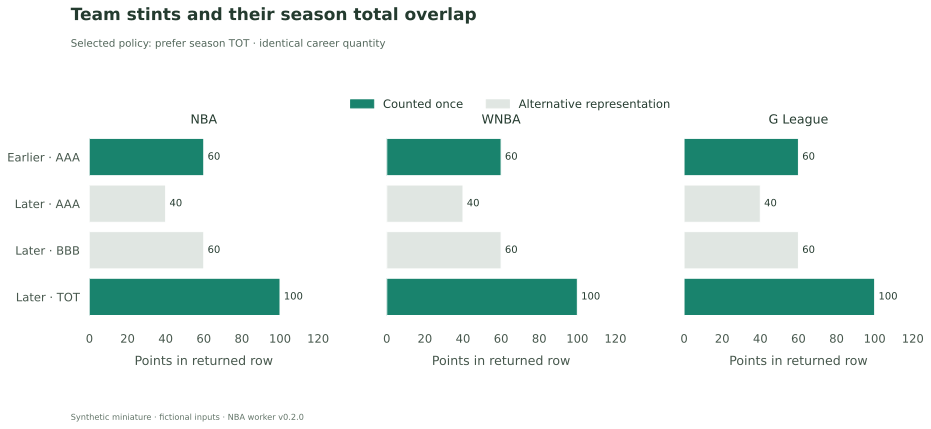

In [11]:
display(rows_frame)
fig, axes = plt.subplots(1, 3, figsize=(13, 6.3), sharex=True, sharey=True)
for ax, league in zip(axes, ["nba", "wnba", "gleague"], strict=True):
    rows = rows_frame[rows_frame.league == league]
    y = np.arange(len(rows))
    ax.barh(y, rows.points, color=["#19836D" if v else "#E0E6E2" for v in rows.selected])
    ax.set_yticks(
        y,
        [
            f"{'Earlier' if r.season == rows.season.min() else 'Later'} · {r.team_abbreviation}"
            for r in rows.itertuples()
        ],
    )
    ax.invert_yaxis()
    for j, row in enumerate(rows.itertuples()):
        ax.text(row.points + 2, j, str(row.points), va="center", fontsize=10)
    ax.set_xlim(0, 120)
    ax.set_title(LEAGUE_LABELS[league])
    ax.set_xlabel("Points in returned row")

fig.legend(
    handles=[Patch(color="#19836D", label="Counted once"), Patch(color="#E0E6E2", label="Alternative representation")],
    loc="upper center",
    bbox_to_anchor=(0.54, 0.79),
    ncol=2,
)
finish(
    fig,
    "Team stints and their season total overlap",
    "Selected policy: "
    + ("prefer season TOT" if USE_SEASON_TOTAL else "keep team stints")
    + " · identical career quantity",
    SOURCE,
    name=f"career-rows-{USE_SEASON_TOTAL}",
)

### Reconcile both the career and the selected season

The naive sum includes team stints **and** their total. The canonical sum uses the
selected policy, and the independent career endpoint is its reference. Separately,
the five game lines should sum to the selected later season, not the whole career.
Keep points and games as separate counts. This avoids claiming that a season log
is a complete career or that four career rows represent four independent seasons.

In [12]:
%%sql career_audit <<
WITH rollup AS (
 SELECT league,player_id,sum(points) AS naive_points,
 sum(points) FILTER(WHERE selected) AS selected_points,
 sum(games_played) FILTER(WHERE selected) AS selected_games,
 count(*) FILTER(WHERE selected) AS selected_rows FROM selected_rows GROUP BY ALL
), logs AS (
 SELECT league,player_id,season,sum(points) AS game_log_points,count(*) AS game_log_games
 FROM game_logs GROUP BY ALL
), seasons AS (
 SELECT league,player_id,season,sum(points) AS season_points,sum(games_played) AS season_games
 FROM selected_rows WHERE selected GROUP BY ALL
)
SELECT r.*,t.points AS career_endpoint_points,t.games_played AS career_endpoint_games,
 l.season,l.game_log_points,l.game_log_games,s.season_points,s.season_games
FROM rollup r JOIN career_totals t USING(league,player_id)
JOIN logs l USING(league,player_id) JOIN seasons s USING(league,player_id,season)
ORDER BY league;

,league,player_id,naive_points,selected_points,selected_games,selected_rows,career_endpoint_points,career_endpoint_games,season,game_log_points,game_log_games,season_points,season_games
0,gleague,9001,260.0,160.0,8.0,2,160,8,2025-26,100.0,5,100.0,5.0
1,nba,9001,260.0,160.0,8.0,2,160,8,2025-26,100.0,5,100.0,5.0
2,wnba,9001,260.0,160.0,8.0,2,160,8,2025,100.0,5,100.0,5.0


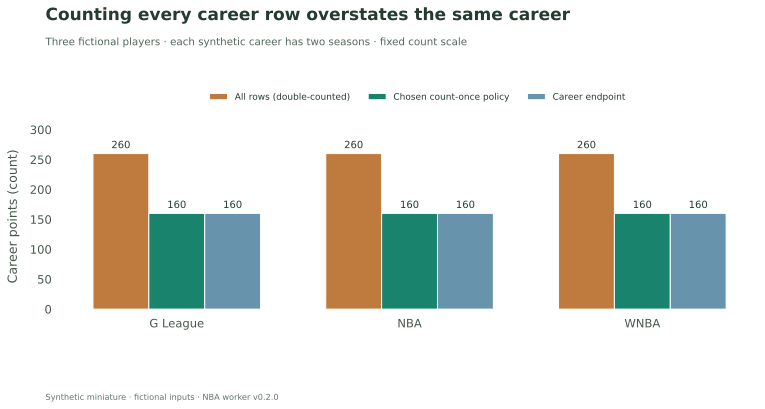

The chosen policy keeps **6 rows** across three schemas. Each career totals **160 points in 8 games**; the selected later-season log contributes **100 points in 5 games**. The naive 260-point sum counts that traded season twice. Switching the representation changes row count, not the underlying career quantity.

In [13]:
display(career_audit)
fig, ax = plt.subplots(figsize=(11, 6.0))
x = np.arange(len(career_audit))
width = 0.24
for shift, column, label, color in [
    (-width, "naive_points", "All rows (double-counted)", "#BF7A3D"),
    (0, "selected_points", "Chosen count-once policy", "#19836D"),
    (width, "career_endpoint_points", "Career endpoint", "#6893AD"),
]:
    bars = ax.bar(x + shift, career_audit[column], width=width, label=label, color=color)
    ax.bar_label(bars, fontsize=10, padding=3)
ax.set_xticks(x, career_audit.league.map(LEAGUE_LABELS))
ax.set_ylim(0, 310)
ax.set_ylabel("Career points (count)")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.54, 0.79), ncol=3, fontsize=9)
finish(
    fig,
    "Counting every career row overstates the same career",
    "Three fictional players · each synthetic career has two seasons · fixed count scale",
    SOURCE,
    name="career-reconciliation",
)
prose(
    f"The chosen policy keeps **{int(career_audit.selected_rows.sum())} rows** across three schemas. "
    "Each career totals **160 points in 8 games**; the selected later-season log contributes "
    "**100 points in 5 games**. The naive 260-point sum counts that traded season twice. "
    "Switching the representation changes row count, not the underlying career quantity."
)

In [14]:
%%sql checks <<
SELECT 'full-index keys unique' AS check_name,count(*)=count(DISTINCT(league,player_id)) AS passed FROM all_players
UNION ALL SELECT 'active flags match current index',NOT EXISTS(SELECT 1 FROM all_players p LEFT JOIN active_players a USING(league,player_id)WHERE p.is_active<>(a.player_id IS NOT NULL))
UNION ALL SELECT 'roster resolves selected history',count(*)=3 FROM rosters r JOIN active_players a USING(league,player_id)WHERE player_id=9001
UNION ALL SELECT 'one total per traded season',NOT EXISTS(SELECT league,player_id,season FROM career_rows WHERE is_multi_team_total GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'no mixed selected representation',NOT EXISTS(SELECT league,player_id,season FROM selected_rows WHERE selected GROUP BY ALL HAVING bool_or(is_multi_team_total) AND bool_or(NOT is_multi_team_total))
UNION ALL SELECT 'career points reconcile',NOT EXISTS(SELECT 1 FROM (SELECT league,player_id,sum(points) p FROM selected_rows WHERE selected GROUP BY ALL)s JOIN career_totals t USING(league,player_id)WHERE s.p<>t.points)
UNION ALL SELECT 'career games reconcile',NOT EXISTS(SELECT 1 FROM (SELECT league,player_id,sum(games_played) g FROM selected_rows WHERE selected GROUP BY ALL)s JOIN career_totals t USING(league,player_id)WHERE s.g<>t.games_played)
UNION ALL SELECT 'player-game keys unique',count(*)=count(DISTINCT(league,player_id,game_id)) FROM game_logs
UNION ALL SELECT 'season points match game log',NOT EXISTS(SELECT 1 FROM (SELECT league,player_id,season,sum(points) p FROM selected_rows WHERE selected GROUP BY ALL)s JOIN (SELECT league,player_id,season,sum(points) p FROM game_logs GROUP BY ALL)g USING(league,player_id,season) WHERE s.p<>g.p)
UNION ALL SELECT 'two seasons per career',NOT EXISTS(SELECT league,player_id FROM selected_rows WHERE selected GROUP BY ALL HAVING count(DISTINCT season)<>2);

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-04.json").write_text(
    json.dumps(
        {
            "parameters": {"USE_SEASON_TOTAL": USE_SEASON_TOTAL},
            "identity": identity.to_dict("records"),
            "rows_frame": rows_frame.to_dict("records"),
            "career_audit": career_audit.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,full-index keys unique,True
1,active flags match current index,True
2,roster resolves selected history,True
3,one total per traded season,True
4,no mixed selected representation,True
5,career points reconcile,True
6,career games reconcile,True
7,player-game keys unique,True
8,season points match game log,True
9,two seasons per career,True


**All 10 SQL checks passed.** Exactly 12 approved API requests; each once, all parameters matched.

7959

### Change one thing

Change **USE_SEASON_TOTAL True→False**. Selected row count should increase from two to three per career, but career points, games, and the later-season reconciliation must remain identical. The first chart changes which representation is filled; the second chart remains the same. This equivalence depends on correct and complete team-stint/total relationships, which the SQL checks make explicit.

In [16]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nba](https://github.com/Query-farm/vgi-nba)